# 04 — Business Impact & Lending Strategy (Lending Club)

Final stage of the credit-risk project: translate the three champion models (logistic regression baseline, fixed-parameter LightGBM, tuned LightGBM) into lending economics on the untouched 2016–2018 out-of-time test window, and recommend the model and approval policy that maximize financial value — not just AUC.

**Approach**

* Reuse the fitted MLflow artifacts — no retraining
* Recalibrate raw scores (isotonic, out-of-fold on the train window) into usable PDs before any money math
* Portfolio simulation at equal approval rates (30–90%) on identical OOT test data
* Expected credit loss = PD × LGD × EAD; net profit from documented loan unit economics; realized P&L uses actual historical outcomes
* Strategies selected on the train window only — the test set is a one-pass evaluation

In [0]:
# LightGBM is not preinstalled on this compute — needed to unpickle the LightGBM
# artifacts loaded from MLflow. Must run first in each new session (auto-restarts
# the Python process; later cells re-define everything).

%pip install lightgbm

In [0]:
# Rebuild the EXACT modeling matrices the champion models were trained on —
# replicating the feature_engineering notebook cell-for-cell (same encodings, same
# 2016-01-01 temporal cutoff, one-hot fitted on train only), so the loaded MLflow
# artifacts score with zero column drift.

import numpy as np
import pandas as pd

df_lending_club = spark.read.table('workspace.default.lending_club_cleaned').toPandas()

# --- simple mappings + ordinal grades (identical to feature_engineering) ---
df_lending_club['term'] = df_lending_club['term'].str.strip().str.replace(' months', '').astype(int)
df_lending_club['initial_list_status'] = df_lending_club['initial_list_status'].map({'w': 1, 'f': 0})
df_lending_club['application_type'] = df_lending_club['application_type'].map({'Individual': 0, 'Joint App': 1})
df_lending_club['grade'] = df_lending_club['grade'].map({g: i for i, g in enumerate('ABCDEFG')})
df_lending_club['sub_grade'] = [(ord(s[0]) - 65) * 5 + int(s[1]) - 1 for s in df_lending_club['sub_grade']]

# --- credit history length ---
cr_line = pd.to_datetime(df_lending_club['earliest_cr_line'], format='%b-%Y')
issue = pd.to_datetime(df_lending_club['issue_d'], format='%b-%Y')
df_lending_club['credit_history_months'] = (
    (issue.dt.year - cr_line.dt.year) * 12 + (issue.dt.month - cr_line.dt.month)
).clip(lower=0)

# --- collapse rare categories ---
df_lending_club['home_ownership'] = df_lending_club['home_ownership'].replace({'ANY': 'OTHER', 'NONE': 'OTHER'})
df_lending_club['purpose'] = df_lending_club['purpose'].replace({'educational': 'other'})

# --- drop non-feature columns, temporal split, one-hot fit on train only ---
df_lending_club = df_lending_club.drop(
    columns=['loan_status', 'funded_amnt', 'funded_amnt_inv', 'addr_state', 'earliest_cr_line'])

train_df = df_lending_club[issue < pd.Timestamp('2016-01-01')].reset_index(drop=True)
test_df = df_lending_club[issue >= pd.Timestamp('2016-01-01')].reset_index(drop=True)
train_df = train_df.drop(columns='issue_d')
test_df = test_df.drop(columns='issue_d')

onehot_cols = ['home_ownership', 'verification_status', 'purpose']
train_encoded = pd.get_dummies(train_df, columns=onehot_cols, drop_first=True, dtype=int)
test_encoded = pd.get_dummies(test_df, columns=onehot_cols, drop_first=True, dtype=int).reindex(
    columns=train_encoded.columns, fill_value=0
)

y_train = train_encoded.pop('loan_default')
y_test = test_encoded.pop('loan_default')
X_train, X_test = train_encoded, test_encoded

print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'default rate — train: {y_train.mean():.1%}, test: {y_test.mean():.1%}')

X_train: (778940, 52), X_test: (517958, 52)
default rate — train: 18.7%, test: 22.4%


In [0]:
# Load the three champion artifacts from MLflow — REUSE, no retraining. Run IDs
# verified in the experiment (all trained on this exact 52-feature matrix, FINISHED):
#   logistic_regression_baseline   0ee58eab  test AUC 0.7070
#   lightgbm_challenger (fixed)   018dcac1  test AUC 0.7141
#   lightgbm_tuned_final          489e950c  test AUC 0.7133

import mlflow
import mlflow.sklearn
from sklearn.metrics import roc_auc_score

MODEL_RUNS = {
    'Logistic Regression': '0ee58eabc2b94fe288f3189910836a26',
    'LightGBM (fixed)':    '018dcac1927c4206a58c9d0d45ad4330',
    'LightGBM (tuned)':    '489e950cec03422897d53aecbb74f746',
}

def feature_names_of(m):
    fn = getattr(m, 'feature_names_in_', None)
    if fn is None:                      # LR pipeline: names live on the scaler step
        fn = m.named_steps['scaler'].feature_names_in_
    return [str(c) for c in fn]

models = {}
for name, run_id in MODEL_RUNS.items():
    m = mlflow.sklearn.load_model(f'runs:/{run_id}/model')
    fn = feature_names_of(m)
    # LightGBM sanitizes stored feature names (spaces -> underscores, e.g. the one-hot
    # 'verification_status_Source Verified' column); LR keeps raw names. Compare
    # sanitized names to confirm identical column ORDER, then predict positionally.
    san = [c.replace(' ', '_') for c in fn]
    cols_san = [c.replace(' ', '_') for c in X_train.columns]
    assert san == cols_san, f'{name}: artifact feature order differs from X_train'
    models[name] = m
    auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    print(f'{name:<22} run {run_id[:8]}  reproduced test AUC {auc:.4f}')

print('\nAll artifacts reproduce their logged test AUCs — matrices align with training.')

Logistic Regression    run 0ee58eab  reproduced test AUC 0.7070


LightGBM (fixed)       run 018dcac1  reproduced test AUC 0.7141


LightGBM (tuned)       run 489e950c  reproduced test AUC 0.7133

All artifacts reproduce their logged test AUCs — matrices align with training.


In [0]:
# --- Calibration, step 1a: out-of-fold scores on the TRAIN window (LR) ---
# All three models were trained with class_weight='balanced', which inflates raw
# probabilities. Before any PD is used in money math, recalibrate with isotonic
# regression fitted on OUT-OF-FOLD train predictions (3-fold CV, shuffled, seed 42).
# The test set plays NO role in calibration.

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict, StratifiedKFold

CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

name = 'Logistic Regression'
oof_lr = cross_val_predict(clone(models[name]), X_train, y_train, cv=CV,
                           method='predict_proba', n_jobs=3)[:, 1]
print(f'{name}: OOF AUC {roc_auc_score(y_train, oof_lr):.4f} | mean raw score {oof_lr.mean():.3f} '
      f'vs actual train default rate {y_train.mean():.3f}')

Logistic Regression: OOF AUC 0.7180 | mean raw score 0.455 vs actual train default rate 0.187


In [0]:
# --- Calibration, step 1b: out-of-fold scores on the TRAIN window (fixed LGBM) ---

name = 'LightGBM (fixed)'
oof_fixed = cross_val_predict(clone(models[name]), X_train, y_train, cv=CV,
                             method='predict_proba', n_jobs=1)[:, 1]
print(f'{name}: OOF AUC {roc_auc_score(y_train, oof_fixed):.4f} | mean raw score {oof_fixed.mean():.3f} '
      f'vs actual train default rate {y_train.mean():.3f}')

LightGBM (fixed): OOF AUC 0.7258 | mean raw score 0.441 vs actual train default rate 0.187


In [0]:
# --- Calibration, step 1c: out-of-fold scores on the TRAIN window (tuned LGBM) ---

name = 'LightGBM (tuned)'
oof_tuned = cross_val_predict(clone(models[name]), X_train, y_train, cv=CV,
                              method='predict_proba', n_jobs=1)[:, 1]
print(f'{name}: OOF AUC {roc_auc_score(y_train, oof_tuned):.4f} | mean raw score {oof_tuned.mean():.3f} '
      f'vs actual train default rate {y_train.mean():.3f}')

LightGBM (tuned): OOF AUC 0.7250 | mean raw score 0.450 vs actual train default rate 0.187


In [0]:
# --- Calibration, step 2: isotonic score→PD mapping + calibrated PDs ---
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

OOF = {'Logistic Regression': oof_lr, 'LightGBM (fixed)': oof_fixed, 'LightGBM (tuned)': oof_tuned}
cal = {}
print('model                  brier(raw)  brier(cal)  mean cal PD  actual test DR')
for name, oof in OOF.items():
    iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds='clip')
    iso.fit(oof, y_train.values)
    raw_test = models[name].predict_proba(X_test)[:, 1]
    test_pd = iso.predict(raw_test)
    cal[name] = {'train_oof_pd': iso.predict(oof), 'test_pd': test_pd}
    print(f'{name:<24}{brier_score_loss(y_test, raw_test):.4f}      {brier_score_loss(y_test, test_pd):.4f}      '
          f'{test_pd.mean():.3f}        {y_test.mean():.3f}')

# NOTE: mean calibrated test PD tracks the 2012-15 train base rate (~18.7%) while the
# OOT window's actual default rate is 22.4% — temporal base-rate drift. Expected-loss
# figures are therefore conservative; realized metrics below use actual outcomes.

# Reliability by decile on the test window — REPORTING ONLY (no decision fitted here)
rel_rows = []
for name in cal:
    d = pd.DataFrame({'pd': cal[name]['test_pd'], 'actual': y_test.values})
    d['decile'] = pd.qcut(d['pd'].rank(method='first'), 10, labels=[f'D{i}' for i in range(1, 11)])
    g = d.groupby('decile', observed=True).agg(avg_cal_pd=('pd', 'mean'), actual_rate=('actual', 'mean'))
    rel_rows.append(g.assign(model=name))
display(pd.concat(rel_rows).reset_index().round(3))

model                  brier(raw)  brier(cal)  mean cal PD  actual test DR
Logistic Regression     0.2069      0.1604      0.176        0.224
LightGBM (fixed)        0.2040      0.1590      0.181        0.224
LightGBM (tuned)        0.2084      0.1588      0.182        0.224


decile,avg_cal_pd,actual_rate,model
D1,0.036,0.048,Logistic Regression
D2,0.068,0.088,Logistic Regression
D3,0.093,0.122,Logistic Regression
D4,0.12,0.156,Logistic Regression
D5,0.144,0.191,Logistic Regression
D6,0.172,0.224,Logistic Regression
D7,0.2,0.266,Logistic Regression
D8,0.233,0.307,Logistic Regression
D9,0.285,0.36,Logistic Regression
D10,0.407,0.481,Logistic Regression


## Financial assumptions (documented; applied identically to every model and policy)

**Population & scope**

* OOT test window 2016–2018: the accepted Lending Club loans issued in that period (exact counts and funded dollars in the simulation table below).
* **Accepted-loans-only limitation:** we observe only applications LC accepted. Approval-rate percentages are shares of that *accepted* population; outcomes for rejected applicants are unknowable from this data, so additional volume effects of tightening beyond LC's own screen are not measured and not claimed.

**Unit economics per loan** — built only from application-time fields (loan_amnt, term, int_rate, installment):

* **Performing loan:** cash in = installment × term (full-term repayment; prepayment ignored — slightly flatters all policies equally). Cost = principal + funding & servicing at **6%/yr** on the average balance (≈ principal/2) over the loan's life (≈5% money cost + ≈1% servicing, in line with 2016–18 conditions).
* **Defaulted loan:** default assumed at mid-term (month term/2). Cash in = installments received until then **plus the recovered share (1−LGD) of the remaining balance**. **EAD** = exact remaining amortized balance at that month; the loss = **LGD 75% × EAD, net of all post-default recoveries — recoveries are counted exactly once, nowhere else (no double counting)**. Cash out = full principal + funding cost on the average balance until default.
* Profit is the investor/lender view; platform fee revenue is not modeled.

**Probabilities & data discipline**

* All models trained with class_weight='balanced' → raw scores overstate PD. Every score used in money math is **isotonic-calibrated on out-of-fold train predictions**; the test set never touches calibration.
* Calibrated PDs inherit the 2012–15 train base rate (18.7%); the OOT window's actual default rate is higher (22.4% — temporal drift), so *expected* figures are conservative while *realized* figures use actual historical outcomes.
* No leakage: financial fields are application-time only; outcomes are used solely for post-hoc evaluation. No test-set optimization: approval rules are fixed financial criteria (approve iff expected profit > 0) or train-window-selected rates; the test set is evaluated once per reported policy.

In [0]:
# --- Loan unit economics (assumptions documented in the markdown cell above) ---
COST_OF_FUNDS = 0.06   # /yr on average outstanding balance: ~5% money cost + ~1% servicing
LGD = 0.75             # net of ALL post-default recoveries (counted nowhere else)

def unit_economics(X, lgd=LGD, cof=COST_OF_FUNDS):
    P = X['loan_amnt'].to_numpy(float)
    n = X['term'].to_numpy(int)
    r = X['int_rate'].to_numpy(float) / 100 / 12
    a = X['installment'].to_numpy(float)
    t_d = n // 2                                          # default assumed at mid-term
    growth = (1 + r) ** n
    ead = P * (growth - (1 + r) ** t_d) / (growth - 1)    # exact amortized balance at t_d
    funding_good = P * 0.5 * (n / 12) * cof
    funding_bad = ((P + ead) / 2) * (t_d / 12) * cof
    return {
        'P': P, 'n': n, 'a': a, 't_d': t_d, 'ead': ead,
        'profit_good': a * n - P - funding_good,                            # fully paid
        'profit_bad': a * t_d + (1 - lgd) * ead - P - funding_bad,          # defaults at mid-term
    }

# sanity: a defaulted loan's P&L must be negative on average at these rates —
# cash in = installments until default + recovered share (1-LGD) of the remaining
# balance; cash out = full principal + funding cost until default. Recoveries are
# counted exactly once (inside the 1-LGD term).
ue_train = unit_economics(X_train)
ue_test = unit_economics(X_test)
assert ue_test['profit_bad'].mean() < 0, 'unit economics sanity check failed'

print(f"test loans: {len(ue_test['P']):,} | avg loan ${ue_test['P'].mean():,.0f} | "
      f"avg rate {X_test['int_rate'].mean():.1f}% | {np.mean(ue_test['n'] == 60):.0%} are 60-month")
print(f"EAD / original balance: {np.mean(ue_test['ead'] / ue_test['P']):.2f} (amortized balance at mid-term)")
print(f"avg profit if performing: ${ue_test['profit_good'].mean():,.0f} "
      f"({np.sum(ue_test['profit_good']) / np.sum(ue_test['P']):.1%} of funded)")
print(f"avg P&L if default: ${ue_test['profit_bad'][y_test.values == 1].mean():,.0f} "
      f"({np.sum(ue_test['profit_bad'][y_test.values == 1]) / np.sum(ue_test['P'][y_test.values == 1]):.1%} of defaulted-loan balance)")

test loans: 517,958 | avg loan $14,458 | avg rate 13.4% | 22% are 60-month
EAD / original balance: 0.56 (amortized balance at mid-term)
avg profit if performing: $2,756 (19.1% of funded)
avg P&L if default: $-3,983 (-25.4% of defaulted-loan balance)


In [0]:
# --- Portfolio simulation at EQUAL approval rates (30%-90%) on the OOT test window ---
# Approval = the lowest-PD ar fraction of accepted applicants (rank-based for exact
# counts; ties inside identical calibrated PDs broken arbitrarily). Baseline =
# approve-all (LC's realized accepted book in the window).

yv = y_test.to_numpy()
g, b = ue_test['profit_good'], ue_test['profit_bad']
P_arr, ead_arr = ue_test['P'], ue_test['ead']
baseline_profit = np.where(yv == 0, g, b).sum()

def policy_row(name, ar, approved, pd_arr):
    funded = P_arr[approved].sum()
    realized_profit = np.where(yv[approved] == 0, g[approved], b[approved]).sum()
    exp_loss = (pd_arr[approved] * LGD * ead_arr[approved]).sum()
    exp_profit = ((1 - pd_arr[approved]) * g[approved] + pd_arr[approved] * b[approved]).sum()
    return {
        'model': name, 'approval_rate': ar, 'n_approved': int(approved.sum()),
        'funded_$M': funded / 1e6,
        'realized_default_rate': yv[approved].mean(),
        'realized_net_profit_$M': realized_profit / 1e6,
        'realized_ROI_%': 100 * realized_profit / funded,
        'expected_net_profit_$M': exp_profit / 1e6,
        'expected_loss_$M': exp_loss / 1e6,
        'EL_rate_%': 100 * exp_loss / funded,
        'incr_profit_vs_approve_all_$M': (realized_profit - baseline_profit) / 1e6,
    }

rows = [policy_row('(baseline) approve-all', 1.00, np.ones(len(yv), bool), np.full(len(yv), yv.mean()))]
for name in cal:
    pd_arr = cal[name]['test_pd']
    rank = pd.Series(pd_arr).rank(method='first').to_numpy()
    for ar in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
        rows.append(policy_row(name, ar, rank <= len(yv) * ar, pd_arr))

sim = pd.DataFrame(rows)
print(f"approve-all baseline: {len(yv):,} loans, ${P_arr.sum()/1e9:.2f}B funded, "
      f"realized default rate {yv.mean():.1%}, realized net profit ${baseline_profit/1e6:,.0f}M")
display(sim.round(3))

approve-all baseline: 517,958 loans, $7.49B funded, realized default rate 22.4%, realized net profit $475M


model,approval_rate,n_approved,funded_$M,realized_default_rate,realized_net_profit_$M,realized_ROI_%,expected_net_profit_$M,expected_loss_$M,EL_rate_%,incr_profit_vs_approve_all_$M
(baseline) approve-all,1.0,517958,7488.582,0.224,474.898,6.342,612.5,711.153,9.496,0.0
Logistic Regression,0.3,155387,2089.828,0.086,28.907,1.383,51.911,54.264,2.597,-445.991
Logistic Regression,0.4,207183,2753.884,0.103,49.338,1.792,84.978,86.902,3.156,-425.56
Logistic Regression,0.5,258979,3422.045,0.121,72.774,2.127,125.496,126.56,3.698,-402.125
Logistic Regression,0.6,310774,4110.973,0.138,101.9,2.479,172.573,175.896,4.279,-372.998
Logistic Regression,0.7,362570,4835.896,0.156,139.63,2.887,234.634,237.215,4.905,-335.268
Logistic Regression,0.8,414366,5619.247,0.175,194.115,3.454,318.058,315.886,5.622,-280.783
Logistic Regression,0.9,466162,6495.552,0.196,289.413,4.456,447.73,427.088,6.575,-185.485
LightGBM (fixed),0.3,155387,2009.686,0.081,24.071,1.198,44.196,48.287,2.403,-450.827
LightGBM (fixed),0.4,207183,2649.827,0.099,46.808,1.766,77.629,78.818,2.974,-428.091


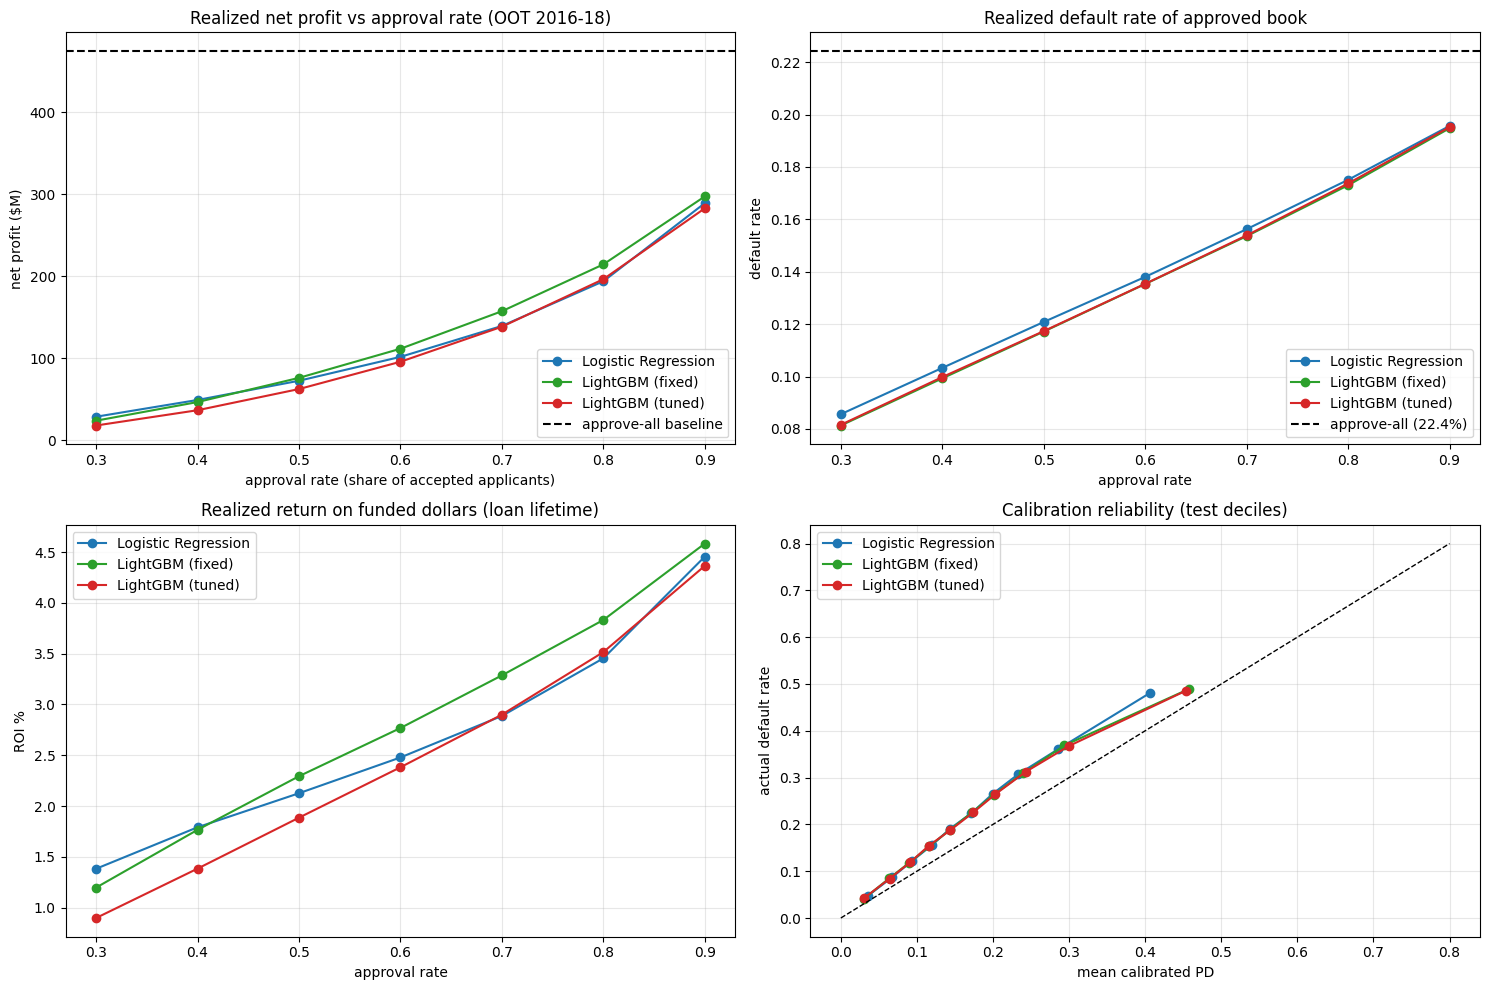

In [0]:
# --- Impact visualizations ---
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
colors = {'Logistic Regression': '#1f77b4', 'LightGBM (fixed)': '#2ca02c', 'LightGBM (tuned)': '#d62728'}

# 1) realized net profit vs approval rate
ax = axes[0, 0]
for name in cal:
    d = sim[sim.model == name]
    ax.plot(d.approval_rate, d['realized_net_profit_$M'], '-o', color=colors[name], label=name)
ax.axhline(baseline_profit / 1e6, color='black', ls='--', label='approve-all baseline')
ax.set(title='Realized net profit vs approval rate (OOT 2016-18)',
       xlabel='approval rate (share of accepted applicants)', ylabel='net profit ($M)')
ax.legend(); ax.grid(alpha=0.3)

# 2) realized default rate of the approved book
ax = axes[0, 1]
for name in cal:
    d = sim[sim.model == name]
    ax.plot(d.approval_rate, d.realized_default_rate, '-o', color=colors[name], label=name)
ax.axhline(yv.mean(), color='black', ls='--', label=f'approve-all ({yv.mean():.1%})')
ax.set(title='Realized default rate of approved book', xlabel='approval rate', ylabel='default rate')
ax.legend(); ax.grid(alpha=0.3)

# 3) realized return on funded dollars
ax = axes[1, 0]
for name in cal:
    d = sim[sim.model == name]
    ax.plot(d.approval_rate, d['realized_ROI_%'], '-o', color=colors[name], label=name)
ax.set(title='Realized return on funded dollars (loan lifetime)',
      xlabel='approval rate', ylabel='ROI %')
ax.legend(); ax.grid(alpha=0.3)

# 4) calibration reliability on the test window (reporting only)
ax = axes[1, 1]
for name in cal:
    d = pd.DataFrame({'pd': cal[name]['test_pd'], 'actual': yv})
    d['decile'] = pd.qcut(d['pd'].rank(method='first'), 10, labels=False)
    gg = d.groupby('decile').agg(pred=('pd', 'mean'), act=('actual', 'mean'))
    ax.plot(gg.pred, gg.act, 'o-', color=colors[name], label=name)
xs = np.linspace(0, 0.8, 2)
ax.plot(xs, xs, 'k--', lw=1)
ax.set(title='Calibration reliability (test deciles)',
       xlabel='mean calibrated PD', ylabel='actual default rate')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [0]:
# --- Optimal lending strategy — SELECTED ON TRAIN, evaluated once on OOT test ---
# Three policies, all decided without touching test outcomes:
#   1. EV rule (threshold-free financial criterion): approve a loan iff its expected
#      profit under the calibrated PD is positive:  (1-PD)*profit_good + PD*profit_bad > 0
#   2. Profit-max fixed approval rate: argmax of EXPECTED profit over a 30-95% sweep,
#      computed on train out-of-fold calibrated PDs
#   3. Risk cap: largest approval rate keeping expected EL <= 6% of funded (train OOF)

gtr, btr = ue_train['profit_good'], ue_train['profit_bad']
Ptr, eadtr = ue_train['P'], ue_train['ead']

def eval_on_test(name, approved, pd_arr, label):
    funded = P_arr[approved].sum()
    rp = np.where(yv[approved] == 0, g[approved], b[approved]).sum()
    el = (pd_arr[approved] * LGD * ead_arr[approved]).sum()
    return {
        'model': name, 'policy': label,
        'approval_rate': approved.mean(),
        'n_approved': int(approved.sum()), 'funded_$M': funded / 1e6,
        'realized_default_rate': yv[approved].mean(),
        'realized_net_profit_$M': rp / 1e6,
        'realized_ROI_%': 100 * rp / funded,
        'EL_rate_%': 100 * el / funded,
        'incr_vs_approve_all_$M': (rp - baseline_profit) / 1e6,
    }

sel_rows, test_policy_rows = [], []
ars = np.arange(0.30, 1.001, 0.05)   # up to 100% so a boundary hit cannot masquerade as an optimum

for name in cal:
    p_tr = cal[name]['train_oof_pd']
    ev_tr = (1 - p_tr) * gtr + p_tr * btr

    # 1) EV rule on train
    appr_tr = ev_tr > 0

    # 2) profit-max fixed rate on train (expected profit at each approval rate)
    rank_tr = pd.Series(p_tr).rank(method='first').to_numpy()
    exp_by_ar = [((1 - p_tr[rank_tr <= len(p_tr) * ar]) * gtr[rank_tr <= len(p_tr) * ar]
                 + p_tr[rank_tr <= len(p_tr) * ar] * btr[rank_tr <= len(p_tr) * ar]).sum() for ar in ars]
    best_ar = float(ars[int(np.argmax(exp_by_ar))])

    # 3) EL cap 6% of funded on train
    el_by_ar = [((p_tr * LGD * eadtr)[rank_tr <= len(p_tr) * ar]).sum()
                / Ptr[rank_tr <= len(p_tr) * ar].sum() for ar in ars]
    ok = [ar for ar, e in zip(ars, el_by_ar) if e <= 0.06]
    cap_ar = max(ok) if ok else float(ars[0])

    sel_rows.append({'model': name,
                     'EV-rule approval rate (train)': appr_tr.mean(),
                     'profit-max rate (train)': best_ar,
                     'EL-cap rate (train)': cap_ar})
    if best_ar == 1.0:
        print(f'{name}: NO PD-rank cutoff beats approve-all on expected profit '
              f'(profit-max rate = 100%) — a PD cutoff cannot remove the thin-margin '
              f'EV-negative loans, which sit mid-distribution. Only the EV rule adds value.')

    # ---- apply each policy to the OOT test set: ONE-PASS evaluation ----
    p_te = cal[name]['test_pd']
    ev_te = (1 - p_te) * g + p_te * b
    rank_te = pd.Series(p_te).rank(method='first').to_numpy()
    test_policy_rows.append(eval_on_test(name, ev_te > 0, p_te, 'EV rule (PD x pricing)'))
    test_policy_rows.append(eval_on_test(name, rank_te <= len(yv) * best_ar, p_te,
                                         f'fixed {best_ar:.0%} (train-selected)'))
    test_policy_rows.append(eval_on_test(name, rank_te <= len(yv) * cap_ar, p_te,
                                         f'EL cap 6% (train-selected {cap_ar:.0%})'))

print('policy selection (train window, OOF calibrated PDs — no test data involved):')
display(pd.DataFrame(sel_rows).round(3))
print('one-pass evaluation of those policies on the OOT 2016-18 test window:')
policies = pd.DataFrame(test_policy_rows)
display(policies.round(3))

policy selection (train window, OOF calibrated PDs — no test data involved):


model,EV-rule approval rate (train),profit-max rate (train),EL-cap rate (train)
Logistic Regression,0.88,1.0,0.8
LightGBM (fixed),0.893,1.0,0.8
LightGBM (tuned),0.914,1.0,0.8


one-pass evaluation of those policies on the OOT 2016-18 test window:


model,policy,approval_rate,n_approved,funded_$M,realized_default_rate,realized_net_profit_$M,realized_ROI_%,EL_rate_%,incr_vs_approve_all_$M
Logistic Regression,EV rule (PD x pricing),0.875,453160,6630.105,0.24,491.587,7.414,8.831,16.688
Logistic Regression,fixed 100% (train-selected),1.0,517957,7488.568,0.224,474.9,6.342,8.272,0.002
Logistic Regression,EL cap 6% (train-selected 80%),0.8,414366,5619.247,0.175,194.115,3.454,5.622,-280.783
LightGBM (fixed),EV rule (PD x pricing),0.888,460164,6717.936,0.235,495.456,7.375,9.219,20.558
LightGBM (fixed),fixed 100% (train-selected),1.0,517957,7488.569,0.224,474.899,6.342,8.702,0.001
LightGBM (fixed),EL cap 6% (train-selected 80%),0.8,414366,5603.434,0.173,214.72,3.832,5.682,-260.179
LightGBM (tuned),EV rule (PD x pricing),0.906,469049,6846.011,0.235,491.161,7.174,9.262,16.263
LightGBM (tuned),fixed 100% (train-selected),1.0,517957,7488.569,0.224,474.899,6.342,8.74,0.001
LightGBM (tuned),EL cap 6% (train-selected 80%),0.8,414366,5593.105,0.174,196.644,3.516,5.709,-278.254


In [0]:
# --- Incremental business impact of the EV-rule policy + assumption sensitivity ---
# Baseline: LC actually funded every accepted applicant in the window (approve-all).
# Incremental profit = policy realized profit - approve-all realized profit.
# EL avoided = approve-all expected loss - policy expected loss (per model's own PDs).

rows = []
for name in cal:
    p_te = cal[name]['test_pd']
    ev_te = (1 - p_te) * g + p_te * b
    appr = ev_te > 0
    el_all = (p_te * LGD * ead_arr).sum()
    el_pol = (p_te[appr] * LGD * ead_arr[appr]).sum()
    pol = policies[(policies.model == name) & (policies.policy == 'EV rule (PD x pricing)')].iloc[0]
    rows.append({
        'model': name,
        'approval_rate': pol['approval_rate'],
        'incremental_profit_$M': pol['incr_vs_approve_all_$M'],
        'uplift_%_of_baseline_profit': 100 * pol['incr_vs_approve_all_$M'] * 1e6 / baseline_profit,
        'EL_avoided_$M': (el_all - el_pol) / 1e6,
    })
print('EV-rule policy vs approve-all baseline (realized outcomes, OOT test):')
display(pd.DataFrame(rows).round(2))

# Sensitivity: re-derive the EV rule and recompute realized profit under different
# LGD / cost-of-funds assumptions. The rule is a financial criterion, not a fitted
# threshold, so this involves no test-set tuning.
name_rec = 'LightGBM (fixed)'   # highest measured business impact (+$20.6M incremental) and best OOT AUC
p_te = cal[name_rec]['test_pd']

sens = []
for lgd in [0.60, 0.75, 0.90]:
    for cof in [0.04, 0.06, 0.08]:
        ue2 = unit_economics(X_test, lgd=lgd, cof=cof)
        ev2 = (1 - p_te) * ue2['profit_good'] + p_te * ue2['profit_bad']
        appr = ev2 > 0
        realized = np.where(yv[appr] == 0, ue2['profit_good'][appr], ue2['profit_bad'][appr]).sum()
        funded = ue2['P'][appr].sum()
        sens.append({'LGD': lgd, 'cost_of_funds': cof,
                     'approval_rate': appr.mean(),
                     'realized_net_profit_$M': realized / 1e6,
                     'realized_ROI_%': 100 * realized / funded})
sens = pd.DataFrame(sens)
print(f"sensitivity of the EV-rule policy ({name_rec}) — realized net profit ($M) by assumption:")
display(sens.pivot(index='LGD', columns='cost_of_funds', values='realized_net_profit_$M').round(0))
display(sens.round(3))

EV-rule policy vs approve-all baseline (realized outcomes, OOT test):


model,approval_rate,incremental_profit_$M,uplift_%_of_baseline_profit,EL_avoided_$M
Logistic Regression,0.87,16.69,3.51,33.92
LightGBM (fixed),0.89,20.56,4.33,32.34
LightGBM (tuned),0.91,16.26,3.42,20.46


sensitivity of the EV-rule policy (LightGBM (fixed)) — realized net profit ($M) by assumption:


0.04,0.06,0.08
892.0,643.0,436.0
735.0,495.0,314.0
581.0,362.0,215.0


LGD,cost_of_funds,approval_rate,realized_net_profit_$M,realized_ROI_%
0.6,0.04,0.999,892.203,11.924
0.6,0.06,0.93,642.889,9.191
0.6,0.08,0.725,435.787,7.822
0.75,0.04,0.994,734.598,9.855
0.75,0.06,0.888,495.456,7.375
0.75,0.08,0.645,313.611,6.262
0.9,0.04,0.978,581.279,7.915
0.9,0.06,0.816,362.31,5.829
0.9,0.08,0.536,214.63,5.065


# Executive summary — business impact & recommended lending strategy

**What was measured.** The three champion models (logistic regression, fixed LightGBM, tuned LightGBM — reused from MLflow, no retraining) were recalibrated to true PDs (isotonic on out-of-fold train predictions; Brier 0.204–0.208 → 0.159) and simulated on the untouched 2016–18 out-of-time window: 517,958 accepted loans, $7.49B funded, 22.4% actual default rate. Money math uses documented unit economics (6%/yr funding+servicing, LGD 75% **net of recoveries**, default at mid-term, EAD = exact amortized balance ≈ 0.56 × balance; performing loan +$2,756 / 19.1% of funded, defaulted loan −$3,983 / −25.4%). All policies were selected on the train window; the test set was evaluated once per policy.

**Baseline.** Approving every accepted applicant (LC's actual behavior) realized **$475M net profit, 6.3% lifetime ROI**, with expected credit loss 9.5% of funded.

**Finding 1 — screening on model risk scores alone destroys value.** At every approval rate from 30% to 90%, for every model, realized profit falls below the approve-all baseline (at 90% approval: $283–298M vs $475M). LC's own pricing already charges for risk: the highest-PD decile (≈49% default rate) still realized ≈18% ROI because those loans carry 20–31% APRs. A PD threshold declines the *most profitable* business first, and no PD-rank cutoff beats approve-all (train profit-max rate = 100% for all three models).

**Finding 2 — the value is in pricing-aware screening: the expected-value (EV) rule.** Approve a loan iff `(1−PD)×profit_good + PD×profit_bad > 0`, using calibrated PD and the loan's own amount, rate and term. This declines the ≈11% of *thin-margin* loans whose risk is not paid for (mostly near-prime, moderate PD, low rate) while keeping well-priced risk. Realized on the OOT window:

| Model | Approval rate | Incremental profit | ROI vs 6.3% baseline | EL avoided |
| --- | --- | --- | --- | --- |
| Logistic Regression | 87.5% | +$16.7M (+3.5%) | 7.41% | $33.9M |
| **LightGBM (fixed) — recommended** | **88.8%** | **+$20.6M (+4.3%)** | **7.38%** | **$32.3M** |
| LightGBM (tuned) | 90.6% | +$16.3M (+3.4%) | 7.17% | $20.5M |

Note the default rate of the EV-rule book *rises* slightly (23.5% vs 22.4%) — by design: risk that is priced for is kept; unprofitable near-prime risk is cut.

**Model recommendation: the fixed LightGBM challenger** (MLflow run 018dcac1; test AUC 0.714, log-loss 0.592) — the highest measured financial impact on every money metric. LR is dominated on all of them. The tuned model gives up ≈$4M of single-window impact in exchange for half the overfit gap and marginally better calibration — a reasonable alternative where stability and monitorability are prioritized.

**Risk management.** A hard EL cap of 6% of funded forces ≈80% approval and costs ≈$260M of realized profit. Use it only if capital or regulatory constraints demand it; otherwise manage risk through the EV rule, EL monitoring, and quarterly recalibration.

**Robustness.** Across LGD 60–90% and funding costs 4–8%, the EV-rule policy stays profitable ($215M–$892M) and adapts its approval rate (100% → 54%) as economics worsen — the recommendation is not an artifact of one assumption set.

**Caveats.** (1) Accepted-loans-only: approval rates are shares of LC's accepted population; rejected applicants' outcomes are unobservable, so effects of screening beyond LC's own acceptance are not claimed. (2) Prepayment is ignored — flatters all policies equally. (3) Calibrated PDs inherit the 2012–15 base rate (18.7% vs 22.4% actual OOT), so expected figures are conservative; realized figures use actual outcomes. (4) One OOT window (2016–18).

**Recommended strategy.** Deploy the fixed LightGBM model with isotonic calibration as the production PD scorer; approve with the EV rule (calibrated PD × per-loan economics) rather than a fixed PD cutoff; monitor realized default rate and calibration drift against the 22.4% OOT benchmark; register the champion to Unity Catalog once signed off. Expected benefit on a book like the test window: **+$20.6M net profit (+4.3%) and ~$32M lower expected credit loss on $6.7B funded, at 88.8% approval**.